# 03 · Visualisation

Ten plots, two click-to-explore charts and a table, delivered two ways from the same figures:

- `clean/dashboard.html` and `clean/performance_table.html`: static pages, plotly.js inlined, open offline from a double-click.
- A Dash site with tabs (Introduction · Data and methods · Results · Conclusion · Limitations · Returns since launch · Attributions), run from the last cell at http://127.0.0.1:8050. Present from this one.

**Question parts**
1. Do equity funds with a higher expense ratio return less?
2. How large is the gap between direct and regular plans?

**Inputs** — `clean/largecap_panel.parquet`, `logs/cleaning_log.csv`, `raw/amfi_fund_performance_largecap_2026-10-24.xlsx`.

**Design rules** — blue is always the Direct plan, orange always the Regular plan, grey is context; the pair differs in lightness as well as hue (ΔE 15.7 under simulated colour blindness) so it reads in greyscale. Where one fund is the point it alone takes colour (Quant, green, in the bubble chart). Two charts per row on one grid; each chart in its own grey card with a plain-English caption that carries a number. No dual axes, no cut-off axes.

## Setup

Palette, Plotly template, `save()` helper. `clean/plots/` is emptied and regenerated.

In [1]:
from pathlib import Path
import re, json
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats

ROOT  = Path("..").resolve()
RAW   = ROOT / "raw"
CLEAN = ROOT / "clean"
LOGS  = ROOT / "logs"
PLOTS = CLEAN / "plots"
PLOTS.mkdir(parents=True, exist_ok=True)
for f in PLOTS.glob("*"):          # regenerate every plot from scratch
    f.unlink()

# palette: two plan colours validated as a colour-blind-safe pair; blue doubles as the
# single highlight on charts where the plans are not both present; grey is context.
C = {"direct": "#2a78d6", "regular": "#eb6834", "grey": "#b8b6b0", "grey_dark": "#6b6a66", "quant": "#1baf7a",
     "ink": "#1c1c1a", "ink2": "#52514e", "surface": "#ffffff", "card": "#f1f3f6", "line": "#e6e4df"}
FONT = "Inter, Segoe UI, Helvetica, Arial, sans-serif"

pio.templates["dcv"] = go.layout.Template(layout=go.Layout(
    font=dict(family=FONT, size=14, color=C["ink"]),
    paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="#ffffff",
    title=dict(font=dict(size=17, color=C["ink"]), x=0, xanchor="left"),
    xaxis=dict(gridcolor=C["line"], zerolinecolor=C["line"], linecolor=C["line"], ticks="outside", tickcolor=C["line"]),
    yaxis=dict(gridcolor=C["line"], zerolinecolor=C["line"], linecolor=C["line"], ticks="outside", tickcolor=C["line"]),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="left", x=0, bgcolor="rgba(0,0,0,0)"),
    margin=dict(l=60, r=24, t=70, b=56), hoverlabel=dict(font_family=FONT),
))
pio.templates.default = "dcv"

def save(fig, name, h=460):
    fig.update_layout(height=h)
    fig.write_html(PLOTS / f"{name}.html", include_plotlyjs="cdn", full_html=True)
    try:
        fig.write_image(PLOTS / f"{name}.png", width=1100, height=h, scale=2)
    except Exception as e:
        print(f"  (png skipped for {name}: {type(e).__name__})")
    return fig

## Data

Fund-level summaries from the panel, joined to the AMFI performance snapshot by normalised name. `top` is the ranking by 3-year Direct return; `best` is the top fund.

In [2]:
panel = pd.read_parquet(CLEAN / "largecap_panel.parquet")
panel["month_dt"] = pd.to_datetime(panel["month"] + "-01")
months = sorted(panel["month"].unique())
print("panel:", panel.shape, "| funds:", panel["name_norm"].nunique(), "| months:", len(months))

# fund-level summaries from the panel
fund = (panel.groupby("name_norm")
             .agg(reg_ter=("reg_ter", "median"), dir_ter=("dir_ter", "median"),
                  gap=("gap", "median"), n_months=("month", "nunique"))
             .reset_index())
def window_return(g):
    g = g.sort_values("month")
    return g["nav_last"].iloc[-1] / g["nav_last"].iloc[0] - 1
wr = (panel.groupby(["name_norm", "plan"]).apply(window_return, include_groups=False)
           .unstack("plan").rename(columns={"Direct": "ret_dir_24m", "Regular": "ret_reg_24m"}).reset_index())
fund = fund.merge(wr, on="name_norm")

# AMFI fund-performance snapshot (hand download, 24-Oct-2026)
perf = pd.read_excel(RAW / "amfi_fund_performance_largecap_2026-10-24.xlsx", sheet_name="Fund_Performance", header=4)
perf = perf[perf["Scheme Name"].notna() & perf["NAV Date"].notna()].copy()
perf["aum_cr"] = pd.to_numeric(perf["Daily AUM (Cr.)"].astype(str).str.replace(r"[\^,]", "", regex=True), errors="coerce")
ren = {"Return 1 Year (%) Regular": "r1_reg", "Return 1 Year (%) Direct": "r1_dir",
       "Return 3 Year (%) Regular": "r3_reg", "Return 3 Year (%) Direct": "r3_dir",
       "Return 5 Year (%) Regular": "r5_reg", "Return 5 Year (%) Direct": "r5_dir",
       "Return 3 Year (%) Benchmark": "r3_bm",
       "Return Since Launch Regular": "rsl_reg", "Return Since Launch Direct": "rsl_dir",
       "Benchmark": "benchmark"}
perf = perf.rename(columns=ren)
def norm_perf(s):
    s = s.lower()
    s = re.sub(r"\blargecap\b", "large cap", s)
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()
perf["name_norm"] = perf["Scheme Name"].map(norm_perf)
perf_date = perf["NAV Date"].max().strftime("%d %b %Y")

fund = fund.merge(perf[["name_norm", "Scheme Name", "benchmark", "aum_cr", "r1_reg", "r1_dir",
                        "r3_reg", "r3_dir", "r5_reg", "r5_dir", "r3_bm", "rsl_reg", "rsl_dir"]],
                  on="name_norm", how="left")
fund["r3_diff"] = fund["r3_dir"] - fund["r3_reg"]
fund["short"] = (fund["name_norm"].str.replace(" large cap fund", "", regex=False)
                                  .str.replace(" fund", "", regex=False).str.title()
                                  .str.replace("Icici", "ICICI").str.replace("Sbi", "SBI").str.replace("Hdfc", "HDFC")
                                  .str.replace("Uti", "UTI").str.replace("Dsp", "DSP").str.replace("Lic Mf", "LIC MF")
                                  .str.replace("Jm", "JM").str.replace("Iti", "ITI").str.replace("Hsbc", "HSBC")
                                  .str.replace("Pgim", "PGIM").str.replace("Bnp", "BNP"))
unmatched = fund[fund["Scheme Name"].isna()]["name_norm"].tolist()
print("funds without a performance-file match:", unmatched)
print("funds with a 3-year return:", fund["r3_dir"].notna().sum())
fund.to_csv(LOGS / "fund_summary.csv", index=False)

top = fund.dropna(subset=["r3_dir"]).sort_values("r3_dir", ascending=False)
best = top.iloc[0]
captions = {}

panel: (1446, 15) | funds: 31 | months: 24
funds without a performance-file match: []
funds with a 3-year return: 28


## Plot 1 — Same fund, two prices (dumbbell)

3-year annualised return, Regular vs Direct, per fund, sorted by Direct.

In [3]:
d = top.sort_values("r3_dir")
fig1 = go.Figure()
for _, r in d.iterrows():
    fig1.add_trace(go.Scatter(x=[r["r3_reg"], r["r3_dir"]], y=[r["short"]] * 2, mode="lines",
                              line=dict(color=C["grey"], width=2), showlegend=False, hoverinfo="skip"))
fig1.add_trace(go.Scatter(x=d["r3_reg"], y=d["short"], mode="markers", name="Regular plan",
                          marker=dict(color=C["regular"], size=10, line=dict(color=C["surface"], width=2)),
                          hovertemplate="%{y}<br>Regular 3-yr: %{x:.2f}% p.a.<extra></extra>"))
fig1.add_trace(go.Scatter(x=d["r3_dir"], y=d["short"], mode="markers", name="Direct plan",
                          marker=dict(color=C["direct"], size=10, line=dict(color=C["surface"], width=2)),
                          hovertemplate="%{y}<br>Direct 3-yr: %{x:.2f}% p.a.<extra></extra>"))
bm = float(top["r3_bm"].median())
fig1.add_vline(x=bm, line=dict(color=C["grey_dark"], width=1), annotation_text=f"benchmark {bm:.1f}%",
               annotation_position="bottom", annotation_font_color=C["ink2"])
fig1.update_layout(title=f"3-year annualised return per fund: Direct beats Regular by {top['r3_diff'].median():.2f} pp a year",
                   xaxis_title="3-year annualised return (% per year, to " + perf_date + ")", yaxis_title="",
                   margin=dict(l=170))
save(fig1, "01_return_dumbbell", h=760)
n_beat = int((top["r3_dir"] > top["r3_bm"]).sum()); n_beat_reg = int((top["r3_reg"] > top["r3_bm"]).sum())
captions["01"] = (f"Each fund's Regular and Direct plan hold the same portfolio, so the horizontal distance is purely the "
                  f"cost of the regular plan: a median {top['r3_diff'].median():.2f} pp of return a year, from "
                  f"{top['r3_diff'].min():.2f} ({top.loc[top['r3_diff'].idxmin(),'short']}) to {top['r3_diff'].max():.2f} "
                  f"({top.loc[top['r3_diff'].idxmax(),'short']}). The spread between funds is far larger than the plan gap: "
                  f"{best['short']} returned {best['r3_dir']:.1f}% a year (Direct) against {top['r3_dir'].min():.1f}% for "
                  f"{top.iloc[-1]['short']}. {n_beat} of {len(top)} Direct plans beat their benchmark over 3 years; only {n_beat_reg} Regular plans did.")
print(captions["01"])

Each fund's Regular and Direct plan hold the same portfolio, so the horizontal distance is purely the cost of the regular plan: a median 1.15 pp of return a year, from 0.18 (Taurus) to 1.81 (Whiteoak Capital). The spread between funds is far larger than the plan gap: Taurus returned 12.7% a year (Direct) against 6.3% for Union. 19 of 28 Direct plans beat their benchmark over 3 years; only 14 Regular plans did.


## Plot 2 — What funds charge (histograms)

In [4]:
med_r, med_d = float(panel["reg_ter"].median()), float(panel["dir_ter"].median())
fig2 = go.Figure()
fig2.add_trace(go.Histogram(x=panel["reg_ter"], name="Regular plan", marker_color=C["regular"], opacity=0.8,
                            xbins=dict(start=0, end=3.2, size=0.1), hovertemplate="TER %{x}%: %{y} fund-months<extra>Regular</extra>"))
fig2.add_trace(go.Histogram(x=panel["dir_ter"], name="Direct plan", marker_color=C["direct"], opacity=0.8,
                            xbins=dict(start=0, end=3.2, size=0.1), hovertemplate="TER %{x}%: %{y} fund-months<extra>Direct</extra>"))
for m, col, lab, pos in [(med_r, C["regular"], "Regular median", "top right"), (med_d, C["direct"], "Direct median", "top left")]:
    fig2.add_vline(x=m, line=dict(color=col, width=2), annotation_text=f"{lab} {m:.2f}%",
                   annotation_position=pos, annotation_font_color=C["ink2"])
fig2.update_layout(barmode="overlay", bargap=0.05, legend=dict(orientation="h", y=-0.28, yanchor="top"), margin=dict(b=90),
                   title=f"Total expense ratio: Regular plans charge {med_r - med_d:.2f} pp a year more than Direct",
                   xaxis_title="Total expense ratio (% of assets per year)", yaxis_title="Fund-months (n = 1,446 per plan)")
save(fig2, "02_ter_distributions")
q = panel[["reg_ter", "dir_ter"]].quantile([0.25, 0.75])
captions["02"] = (f"Every fund-month in the panel, both plans. The Regular distribution sits a full percentage point to the right: "
                  f"median {med_r:.2f}% (IQR {q.loc[0.25,'reg_ter']:.2f} to {q.loc[0.75,'reg_ter']:.2f}) against {med_d:.2f}% "
                  f"(IQR {q.loc[0.25,'dir_ter']:.2f} to {q.loc[0.75,'dir_ter']:.2f}) for Direct. The two distributions barely overlap: "
                  f"{100*(panel['reg_ter'] > panel['dir_ter'].quantile(0.75)).mean():.0f}% of Regular fund-months are costlier than the dearest quarter of Direct fund-months.")
print(captions["02"])

Every fund-month in the panel, both plans. The Regular distribution sits a full percentage point to the right: median 2.02% (IQR 1.68 to 2.34) against 0.87% (IQR 0.67 to 1.05) for Direct. The two distributions barely overlap: 99% of Regular fund-months are costlier than the dearest quarter of Direct fund-months.


## Plot 3 — The Regular plan's extra charge, fund by fund

In [5]:
g = fund.sort_values("gap")
colors = [C["grey"]] * len(g); colors[-1] = C["direct"]
fig3 = go.Figure(go.Bar(x=g["gap"], y=g["short"], orientation="h", marker_color=colors,
                        hovertemplate="%{y}<br>Regular minus Direct TER: %{x:.2f} pp<extra></extra>"))
fig3.update_traces(marker_line_width=0)
fig3.update_layout(title=f"Direct-regular TER gap per fund: {g['gap'].min():.2f} to {g['gap'].max():.2f} pp a year",
                   xaxis_title="Median Regular TER minus Direct TER (percentage points per year)", yaxis_title="",
                   margin=dict(l=170), bargap=0.35)
save(fig3, "03_gap_by_fund", h=760)
captions["03"] = (f"One bar per fund, the median over 24 months. The gap is not a fixed number: it runs from {g['gap'].min():.2f} pp "
                  f"({g.iloc[0]['short']}) to {g['gap'].max():.2f} pp ({g.iloc[-1]['short']}), median {g['gap'].median():.2f} pp. "
                  f"The gap is the distribution commission embedded in the Regular plan, so it says nothing about the fund's skill, "
                  f"only about what the investor pays to buy it through an intermediary.")
print(captions["03"])

One bar per fund, the median over 24 months. The gap is not a fixed number: it runs from 0.18 pp (Taurus) to 1.66 pp (Mahindra Manulife), median 1.11 pp. The gap is the distribution commission embedded in the Regular plan, so it says nothing about the fund's skill, only about what the investor pays to buy it through an intermediary.


## Plot 4 — Does paying more get you more? (plan-matched scatter with OLS)

In [6]:
s = fund.dropna(subset=["r3_dir", "r3_reg"])
fig4 = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.06,
                     subplot_titles=("Direct plan", "Regular plan"))
fits = {}
for col, (ter, ret, name, color) in enumerate([("dir_ter", "r3_dir", "Direct", C["direct"]),
                                               ("reg_ter", "r3_reg", "Regular", C["regular"])], start=1):
    x, y = s[ter].values, s[ret].values
    sl, ic, r, p, se = stats.linregress(x, y)
    fits[name] = (sl, r**2, p)
    fig4.add_trace(go.Scatter(x=x, y=y, mode="markers", name=f"{name} plan", text=s["short"],
                              marker=dict(color=color, size=10, line=dict(color=C["surface"], width=2)),
                              hovertemplate="%{text}<br>TER %{x:.2f}%<br>3-yr return %{y:.2f}% p.a.<extra></extra>"),
                   row=1, col=col)
    xx = np.linspace(x.min(), x.max(), 50)
    fig4.add_trace(go.Scatter(x=xx, y=ic + sl * xx, mode="lines", line=dict(color=C["grey_dark"], width=2),
                              name="OLS fit" if col == 1 else None, showlegend=(col == 1), hoverinfo="skip"), row=1, col=col)
    fig4.add_annotation(x=0.98, y=0.04, xref=f"x{col} domain" if col > 1 else "x domain", yref="y domain",
                        text=f"slope {sl:+.2f} pp per pp of TER<br>R² = {r**2:.2f}, p = {p:.2f}, n = {len(x)}",
                        showarrow=False, xanchor="right", align="right", font=dict(size=12, color=C["ink2"]))
    fig4.update_xaxes(title_text="Median TER over the window (% per year)", row=1, col=col)
fig4.update_yaxes(title_text="3-year annualised return (% per year)", row=1, col=1)
fig4.update_layout(title="Within a plan type, a higher TER does not predict a lower 3-year return")
save(fig4, "04_return_vs_ter", h=480)
captions["04"] = (f"One point per fund, each plan matched to its own TER. If costs drove results, both panels would slope down. "
                  f"They do not: slope {fits['Direct'][0]:+.2f} for Direct (R² {fits['Direct'][1]:.2f}, p = {fits['Direct'][2]:.2f}) and "
                  f"{fits['Regular'][0]:+.2f} for Regular (R² {fits['Regular'][1]:.2f}, p = {fits['Regular'][2]:.2f}). "
                  f"Across funds the TER explains almost none of the return difference; within a fund (Plot 1) it explains all of it. "
                  f"That is why fund performance decides the choice and TER decides the plan.")
print(captions["04"])

One point per fund, each plan matched to its own TER. If costs drove results, both panels would slope down. They do not: slope +0.48 for Direct (R² 0.01, p = 0.61) and +0.78 for Regular (R² 0.02, p = 0.47). Across funds the TER explains almost none of the return difference; within a fund (Plot 1) it explains all of it. That is why fund performance decides the choice and TER decides the plan.


## Plot 5 — The gap never moves (median and IQR by month)

In [7]:
gm = (panel.groupby("month_dt")["gap"].agg(med="median", p25=lambda v: v.quantile(.25), p75=lambda v: v.quantile(.75)).reset_index())
fig5 = go.Figure()
fig5.add_trace(go.Scatter(x=pd.concat([gm["month_dt"], gm["month_dt"][::-1]]), y=pd.concat([gm["p75"], gm["p25"][::-1]]),
                          fill="toself", fillcolor="rgba(42,120,214,0.12)", line=dict(color="rgba(0,0,0,0)"),
                          name="Interquartile range across funds", hoverinfo="skip"))
fig5.add_trace(go.Scatter(x=gm["month_dt"], y=gm["med"], mode="lines+markers", name="Median gap",
                          line=dict(color=C["direct"], width=2), marker=dict(size=8, line=dict(color=C["surface"], width=2)),
                          hovertemplate="%{x|%b %Y}<br>median gap %{y:.2f} pp<extra></extra>"))
fig5.update_layout(title=f"The gap is stable: median between {gm['med'].min():.2f} and {gm['med'].max():.2f} pp in every month",
                   xaxis_title="Month", yaxis_title="Regular minus Direct TER (pp per year)", yaxis_range=[0, 2])
save(fig5, "05_gap_over_time", h=400)
captions["05"] = (f"Median across the 31 funds each month, with the interquartile band. The line moves within "
                  f"{gm['med'].max() - gm['med'].min():.2f} pp over 24 months and never trends; the band stays about "
                  f"{(gm['p75'] - gm['p25']).mean():.2f} pp wide. The cost of choosing Regular over Direct is a fixed feature of the "
                  f"category, not something that varies with the market.")
print(captions["05"])

Median across the 31 funds each month, with the interquartile band. The line moves within 0.07 pp over 24 months and never trends; the band stays about 0.60 pp wide. The cost of choosing Regular over Direct is a fixed feature of the category, not something that varies with the market.


## Plot 6 — ₹1,000 a month, two years (SIP value)

The per-fund `sip` frame built here is reused by the click-to-explore SIP chart.

In [8]:
SIP = 1000
rows = []
for (n, pl), gq in panel.sort_values("month_dt").groupby(["name_norm", "plan"]):
    units = (SIP / gq["nav_last"]).cumsum()
    rows.append(pd.DataFrame({"name_norm": n, "plan": pl, "month_dt": gq["month_dt"].values,
                              "invested": SIP * np.arange(1, len(gq) + 1), "value": (units * gq["nav_last"]).values}))
sip = pd.concat(rows)
full = fund.loc[fund["n_months"] == len(months), "name_norm"]            # funds present all 24 months
sipm = (sip[sip["name_norm"].isin(full)].groupby(["plan", "month_dt"])["value"].median().unstack("plan").reset_index())
sipm["invested"] = SIP * np.arange(1, len(sipm) + 1)
end = sipm.iloc[-1]
fig6 = go.Figure()
fig6.add_trace(go.Scatter(x=sipm["month_dt"], y=sipm["invested"], mode="lines", name="Amount invested",
                          line=dict(color=C["grey_dark"], width=2, dash="dot"), hovertemplate="%{x|%b %Y}<br>invested ₹%{y:,.0f}<extra></extra>"))
fig6.add_trace(go.Scatter(x=sipm["month_dt"], y=sipm["Regular"], mode="lines", name="Regular plan",
                          line=dict(color=C["regular"], width=2), hovertemplate="%{x|%b %Y}<br>Regular ₹%{y:,.0f}<extra></extra>"))
fig6.add_trace(go.Scatter(x=sipm["month_dt"], y=sipm["Direct"], mode="lines", name="Direct plan",
                          line=dict(color=C["direct"], width=2), hovertemplate="%{x|%b %Y}<br>Direct ₹%{y:,.0f}<extra></extra>"))
for pl, col in [("Regular", C["regular"]), ("Direct", C["direct"])]:
    fig6.add_annotation(x=end["month_dt"], y=end[pl], text=f"₹{end[pl]:,.0f}", showarrow=False, xanchor="left", xshift=6,
                        font=dict(color=C["ink2"], size=12))
fig6.update_layout(title=f"₹{SIP:,} a month for 24 months: Direct ends ₹{end['Direct'] - end['Regular']:,.0f} ahead of Regular",
                   xaxis_title="Month", yaxis_title="Value of the SIP (₹)", margin=dict(r=70))
save(fig6, "06_sip_value", h=420)
captions["06"] = (f"The median fund's path for an investor putting in ₹{SIP:,} on the last trading day of each month. After 24 months "
                  f"₹{end['invested']:,.0f} invested is worth ₹{end['Regular']:,.0f} in Regular and ₹{end['Direct']:,.0f} in Direct, "
                  f"a {100*(end['Direct']/end['Regular'] - 1):.2f}% difference. The window was a flat-to-down market, which is why both "
                  f"lines sit near the invested amount; the Direct advantage compounds at the TER gap regardless of market direction.")
print(captions["06"])

The median fund's path for an investor putting in ₹1,000 on the last trading day of each month. After 24 months ₹24,000 invested is worth ₹23,197 in Regular and ₹23,428 in Direct, a 1.00% difference. The window was a flat-to-down market, which is why both lines sit near the invested amount; the Direct advantage compounds at the TER gap regardless of market direction.


## Plot 7 — All funds move together (emphasis)

In [9]:
ld = panel[(panel["plan"] == "Direct")].dropna(subset=["monthly_return"]).sort_values("month_dt")
ld["ret_pct"] = 100 * ld["monthly_return"]
med_path = ld.groupby("month_dt")["ret_pct"].median().reset_index()
corr = ld.pivot(index="month_dt", columns="name_norm", values="ret_pct").corr()
mean_corr = corr.where(~np.eye(len(corr), dtype=bool)).stack().mean()
fig7 = go.Figure()
for n, gq in ld.groupby("name_norm"):
    if n == best["name_norm"]:
        continue
    fig7.add_trace(go.Scatter(x=gq["month_dt"], y=gq["ret_pct"], mode="lines", line=dict(color=C["grey"], width=1.2),
                              name="Other funds", showlegend=False, hovertemplate=f"{fund.set_index('name_norm').loc[n,'short']}<br>%{{x|%b %Y}}: %{{y:.2f}}%<extra></extra>"))
fig7.add_trace(go.Scatter(x=[None], y=[None], mode="lines", line=dict(color=C["grey"], width=1.2), name="Other 30 funds"))
fig7.add_trace(go.Scatter(x=med_path["month_dt"], y=med_path["ret_pct"], mode="lines", name="Category median",
                          line=dict(color=C["ink"], width=2), hovertemplate="median %{x|%b %Y}: %{y:.2f}%<extra></extra>"))
bq = ld[ld["name_norm"] == best["name_norm"]]
fig7.add_trace(go.Scatter(x=bq["month_dt"], y=bq["ret_pct"], mode="lines", name=f"{best['short']} (best 3-yr return)",
                          line=dict(color=C["direct"], width=2.5), hovertemplate=f"{best['short']}<br>%{{x|%b %Y}}: %{{y:.2f}}%<extra></extra>"))
fig7.update_layout(title=f"Monthly returns of all 31 funds move as a block (mean pairwise correlation {mean_corr:.2f})",
                   xaxis_title="Month", yaxis_title="Monthly return, Direct plan (%)")
save(fig7, "07_all_funds_monthly", h=420)
captions["07"] = (f"Direct-plan monthly returns, every fund in grey, the category median in black and the best 3-year performer "
                  f"highlighted. The average correlation between any two funds is {mean_corr:.2f}; the worst month "
                  f"({med_path.loc[med_path['ret_pct'].idxmin(),'month_dt']:%b %Y}, {med_path['ret_pct'].min():.1f}%) and the best "
                  f"({med_path.loc[med_path['ret_pct'].idxmax(),'month_dt']:%b %Y}, {med_path['ret_pct'].max():+.1f}%) hit every fund. "
                  f"A 1 pp annual TER drag is 0.08 pp a month, invisible against monthly swings of several points; "
                  f"it only shows up when the same portfolio is compared with itself (Plot 1).")
print(captions["07"])

Direct-plan monthly returns, every fund in grey, the category median in black and the best 3-year performer highlighted. The average correlation between any two funds is 0.95; the worst month (Mar 2026, -11.3%) and the best (Apr 2026, +8.1%) hit every fund. A 1 pp annual TER drag is 0.08 pp a month, invisible against monthly swings of several points; it only shows up when the same portfolio is compared with itself (Plot 1).


## Plot 8 — Before and after cleaning

Row count per cleaning step (dot plot on a labelled log axis) and distinct spellings before/after, from `logs/cleaning_log.csv`.

In [10]:
clog = pd.read_csv(LOGS / "cleaning_log.csv")
steps = clog[clog["step"].isin(["NAV large-cap filter (NSDL LCF via dict)", "NAV growth-only filter", "drop JioBlackRock",
                                "drop off-calendar NAV rows", "aggregate to monthly panel"])].copy()
funnel = pd.DataFrame({"stage": ["All NAV rows, 24 months", "Large-cap schemes", "Growth option only",
                                 "TER matched, JioBlackRock dropped", "Weekend NAVs dropped", "Monthly panel"],
                       "rows": [int(steps.iloc[0]["rows_before"])] + steps["rows_after"].astype(int).tolist()})
audit_note = clog.loc[clog["step"] == "normalisation audit", "note"].iloc[0]
pairs = {k: (int(a), int(b)) for k, a, b in re.findall(r"(Option|Plan|NAV Name) (\d+)\u2192(\d+)", audit_note)}
fig8 = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45], horizontal_spacing=0.14,
                     subplot_titles=("Rows at each cleaning step", "Distinct spellings per field"))
# dot plot, not bars: on a log axis a bar's length would misstate the ratio (misleading-charts lecture)
fig8.add_trace(go.Scatter(x=funnel["rows"], y=funnel["stage"], mode="markers+text",
                          marker=dict(color=[C["grey_dark"]] * 5 + [C["direct"]], size=12, line=dict(color=C["surface"], width=2)),
                          text=[f"{v:,}" for v in funnel["rows"]], textposition="middle right", textfont=dict(color=C["ink2"], size=12),
                          cliponaxis=False, hovertemplate="%{y}: %{x:,} rows<extra></extra>", showlegend=False), row=1, col=1)
fields = list(pairs.keys())
fig8.add_trace(go.Bar(x=fields, y=[pairs[f][0] for f in fields], name="Before cleaning", marker_color=C["grey"],
                      text=[pairs[f][0] for f in fields], textposition="outside", hovertemplate="%{x} before: %{y}<extra></extra>"), row=1, col=2)
fig8.add_trace(go.Bar(x=fields, y=[pairs[f][1] for f in fields], name="After cleaning", marker_color=C["direct"],
                      text=[pairs[f][1] for f in fields], textposition="outside", hovertemplate="%{x} after: %{y}<extra></extra>"), row=1, col=2)
fig8.update_xaxes(type="log", title_text="Rows (log scale)", range=[2.9, 7.1], row=1, col=1)
fig8.update_yaxes(autorange="reversed", row=1, col=1)
fig8.update_yaxes(title_text="Distinct values", row=1, col=2)
fig8.update_layout(title="Before and after cleaning: 4.26 million daily rows become a 1,446-row monthly panel",
                   bargap=0.35, margin=dict(l=230, b=80), legend=dict(orientation="h", y=-0.22, yanchor="top", x=0.55))
save(fig8, "08_before_after_cleaning", h=440)
captions["08"] = (f"Left: the row count at each step of the cleaning log, from {funnel['rows'].iloc[0]:,} daily NAV rows for every scheme "
                  f"to {funnel['rows'].iloc[-1]:,} fund-plan-months. Right: the string fields that had to be normalised before the two "
                  f"feeds could be joined; the Option field alone had {pairs['Option'][0]} spellings of the growth/IDCW choice, "
                  f"and 62 NAV names mapped to 31 funds after 12 in-window renames were resolved through the NSDL code.")
print(captions["08"])
json.dump(captions, open(LOGS / "plot_captions.json", "w"), indent=2)

Left: the row count at each step of the cleaning log, from 4,255,618 daily NAV rows for every scheme to 1,446 fund-plan-months. Right: the string fields that had to be normalised before the two feeds could be joined; the Option field alone had 13 spellings of the growth/IDCW choice, and 62 NAV names mapped to 31 funds after 12 in-window renames were resolved through the NSDL code.


## Page helpers

Headline numbers, attribution block, fonts and CSS shared by the static pages and the Dash site.

In [11]:
import plotly.offline
from html import escape

def frag(fig):
    return fig.to_html(full_html=False, include_plotlyjs=False, config={"displaylogo": False, "responsive": True,
                       "modeBarButtonsToRemove": ["lasso2d", "select2d"]})

def fmt(v, d=1, signed=False):
    if pd.isna(v):
        return "<span class='na'>n/a</span>"
    return f"{v:+.{d}f}" if signed else f"{v:.{d}f}"

# headline numbers
k_funds   = fund["name_norm"].nunique()
k_gap_ter = panel["gap"].median()
k_gap_ret = top["r3_diff"].median()
k_worst   = top.iloc[-1]

# 10-year SIP at the median return gap: 10% a year vs 10% minus the gap
def sip_fv(annual, n=120, amt=SIP):
    m = (1 + annual) ** (1 / 12) - 1
    return amt * (((1 + m) ** n - 1) / m) * (1 + m)
gap_dec = top["r3_diff"].median() / 100
ten_yr_pct = 100 * (1 - sip_fv(0.10 - gap_dec) / sip_fv(0.10))

kpis = [("funds studied", f"{k_funds}", "large cap, both plans, 24 months"),
        ("extra fee in a Regular plan", f"{k_gap_ter:.1f}% a year", "of your money, every year"),
        ("extra return in a Direct plan", f"+{k_gap_ret:.1f}% a year", "same fund, same shares"),
        ("best vs worst fund, 3 years", f"{best['r3_dir']:.1f}% vs {k_worst['r3_dir']:.1f}%", f"{best['short']} vs {k_worst['short']}, a year")]

attribution = """
<h3>Data sources and licence</h3>
<ul><li>AMFI (Association of Mutual Funds in India), www.amfiindia.com: NAV history, Total Expense Ratio data and fund-performance data.
Used under AMFI's terms of use for personal, non-commercial purposes. AMFI gives no guarantee of accuracy. Not redistributed.</li></ul>
<h3>Software</h3>
<ul><li>Python, pandas, NumPy, SciPy, Plotly and Dash with dash-bootstrap-components, openpyxl, pyarrow, requests, amfipy, Jupyter.</li></ul>
<h3>AI tools</h3>
<ul><li>AI tools were used for small pieces of code help. All code was run and checked by the team; every number on this site is computed from the data in the notebooks.</li></ul>
<h3>Contributions</h3>
<table class="contrib"><thead><tr><th>Member</th><th>Work</th></tr></thead><tbody>
<tr><td>Soham</td><td>100%: data collection, storage, cleaning, visualisation, site and presentation</td></tr>
</tbody></table>"""

FONT_LINK = '<link rel="preconnect" href="https://fonts.googleapis.com"><link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap" rel="stylesheet">'
FONT = "Inter, Segoe UI, Helvetica, Arial, sans-serif"

# shared look: hero band, grey cards, big type
css = f"""
:root{{--ink:{C['ink']};--ink2:{C['ink2']};--muted:#7d7c78;--bg:#ffffff;--card:{C['card']};--line:{C['line']};
--direct:{C['direct']};--regular:{C['regular']};--navy:#14213d}}
*{{box-sizing:border-box}}
body{{margin:0;background:var(--bg);color:var(--ink);font-family:{FONT};font-size:17px;line-height:1.6}}
.wrap{{max-width:1240px;margin:0 auto;padding:0 24px}}
.hero{{background:linear-gradient(135deg,#14213d 0%,#1f3a93 55%,#2a78d6 100%);color:#fff;padding:56px 0 40px}}
.hero .eyebrow{{font-size:14px;letter-spacing:.08em;text-transform:uppercase;opacity:.8;margin:0 0 10px}}
.hero h1{{font-size:38px;line-height:1.2;font-weight:800;margin:0 0 28px;letter-spacing:-0.01em;max-width:900px}}
.stats{{display:grid;grid-template-columns:repeat(auto-fit,minmax(200px,1fr));gap:16px;margin:0 0 20px}}
.stat{{background:rgba(255,255,255,.12);border:1px solid rgba(255,255,255,.25);border-radius:14px;padding:16px 18px}}
.stat .v{{font-size:30px;font-weight:800;line-height:1.1}} .stat .l{{font-size:14px;opacity:.9;margin-top:6px}}
.hero .meta{{font-size:14px;opacity:.85;margin:0}} .hero a{{color:#fff}}
nav{{position:sticky;top:0;z-index:5;background:rgba(255,255,255,.94);backdrop-filter:blur(6px);border-bottom:1px solid var(--line)}}
nav .wrap{{display:flex;gap:22px;flex-wrap:wrap;padding:12px 24px;font-size:15px;font-weight:600}}
nav a{{color:var(--ink2);text-decoration:none}} nav a:hover{{color:var(--direct)}}
main{{padding-bottom:64px}}
section{{margin-top:56px}}
h2{{font-size:28px;font-weight:800;margin:0 0 14px;letter-spacing:-0.01em}}
h3{{font-size:18px;font-weight:700;margin:22px 0 8px}} h4{{font-size:17px;font-weight:700;margin:4px 0 10px}}
.prose{{background:var(--card);border-radius:16px;padding:24px 28px;max-width:960px}}
.prose h3:first-child{{margin-top:0}} .prose ul,.prose ol{{padding-left:22px;margin:8px 0}} .prose li{{margin:6px 0}}
.big{{font-size:19px}}
.row2{{display:grid;grid-template-columns:repeat(auto-fit,minmax(480px,1fr));gap:20px;margin-top:20px}}
figure{{margin:0;background:var(--card);border-radius:16px;padding:18px 18px 16px;display:flex;flex-direction:column}}
.plot{{width:100%;background:#fff;border-radius:10px;padding:6px}}
figcaption{{padding:12px 4px 0;font-size:15px;color:var(--ink2)}}
.tablewrap{{overflow-x:auto;background:var(--card);border-radius:16px;padding:8px}}
table#perf{{border-collapse:collapse;width:100%;font-size:15px;font-variant-numeric:tabular-nums;background:#fff;border-radius:10px;overflow:hidden}}
#perf th{{background:#e9ecf1;color:var(--ink2);font-weight:700;padding:10px 12px;text-align:right;cursor:pointer;white-space:nowrap;user-select:none}}
#perf th span{{display:block;font-weight:400;font-size:12px;color:var(--muted)}}
#perf th.l,#perf td.l{{text-align:left}}
#perf td{{padding:9px 12px;text-align:right;border-top:1px solid var(--line)}}
#perf th.sorted::after{{content:" ▾";color:var(--direct)}} #perf th.sorted.asc::after{{content:" ▴"}}
.na{{color:var(--muted)}} .note{{font-size:14px;color:var(--muted);margin:10px 2px 0}}
.sw{{display:inline-block;width:12px;height:12px;border-radius:3px;vertical-align:-1px;margin-right:3px}}
table.contrib{{border-collapse:collapse;font-size:15px;margin-top:6px;background:#fff}} .contrib th,.contrib td{{border:1px solid var(--line);padding:8px 14px;text-align:left}}
code{{font-family:ui-monospace,SFMono-Regular,Menlo,monospace;font-size:14px;background:#e9ecf1;padding:1px 6px;border-radius:4px}}
footer{{color:var(--muted);font-size:13px;text-align:center;padding:24px}}
@media (max-width:640px){{.row2{{grid-template-columns:1fr}} .hero h1{{font-size:28px}} body{{font-size:16px}}}}
"""

# same look inside Dash (Bootstrap FLATLY underneath)
DASH_CSS = f"""
body{{font-family:{FONT};font-size:17px;color:{C['ink']};background:#fff}}
.hero{{background:linear-gradient(135deg,#14213d 0%,#1f3a93 55%,#2a78d6 100%);color:#fff;padding:56px 0 36px}}
.hero .eyebrow{{font-size:14px;letter-spacing:.08em;text-transform:uppercase;opacity:.8;margin-bottom:10px}}
.hero h1{{font-size:38px;line-height:1.2;font-weight:800;margin-bottom:28px;letter-spacing:-0.01em;max-width:900px}}
.hero .stats{{margin-bottom:12px}}
.stat{{background:rgba(255,255,255,.12);border:1px solid rgba(255,255,255,.25);border-radius:14px;padding:16px 18px;margin-bottom:12px;height:calc(100% - 12px)}}
.stat .v{{font-size:28px;font-weight:800;line-height:1.1}} .stat .l{{font-size:14px;opacity:.9;margin-top:6px}} .stat .s{{font-size:12px;opacity:.7}}
.hero .meta{{font-size:14px;opacity:.85;margin:0}}
.tabs .nav-link{{font-weight:600;font-size:16px;color:{C['ink2']};border:none;border-bottom:3px solid transparent}}
.tabs .nav-link.active{{color:{C['direct']};border-bottom-color:{C['direct']};background:transparent}}
.card.viz,.card.prose{{background:{C['card']};border:none;border-radius:16px;margin-top:20px}}
.card.viz .card-title{{font-size:17px;font-weight:700;margin-bottom:8px}}
.card.viz .js-plotly-plot{{background:#fff;border-radius:10px}}
.card.viz .cap{{font-size:15px;color:{C['ink2']};margin:12px 2px 0}}
.card.prose h3{{font-size:18px;font-weight:700;margin:22px 0 8px}} .card.prose h3:first-child{{margin-top:0}}
.card.prose .big{{font-size:19px}} .card.prose li{{margin:6px 0}}
.card.prose code{{background:#e9ecf1;color:{C['ink']};padding:1px 6px;border-radius:4px}}
.sw{{display:inline-block;width:12px;height:12px;border-radius:3px;vertical-align:-1px;margin-right:3px}}
table.contrib{{border-collapse:collapse;background:#fff}} .contrib th,.contrib td{{border:1px solid {C['line']};padding:8px 14px}}
table.perf{{background:#fff;border-radius:10px;overflow:hidden;font-variant-numeric:tabular-nums}} table.perf th{{background:#e9ecf1}}
table.perf td:not(:first-child),table.perf th:not(:first-child){{text-align:right}}
"""

js = """
document.querySelectorAll('#perf th').forEach(function(th, idx){
  th.addEventListener('click',function(){
    var table=th.closest('table'), tbody=table.querySelector('tbody');
    var asc = th.classList.contains('sorted') && !th.classList.contains('asc');
    table.querySelectorAll('th').forEach(function(x){x.classList.remove('sorted','asc')});
    th.classList.add('sorted'); if(asc) th.classList.add('asc');
    var rows=Array.from(tbody.querySelectorAll('tr'));
    rows.sort(function(r1,r2){
      var a=r1.children[idx].textContent.trim(), c=r2.children[idx].textContent.trim();
      var na=parseFloat(a), nc=parseFloat(c);
      var va=isNaN(na)?a.toLowerCase():na, vb=isNaN(nc)?c.toLowerCase():nc;
      if(isNaN(na)&&!isNaN(nc)) return 1; if(!isNaN(na)&&isNaN(nc)) return -1;
      if(va<vb) return asc?-1:1; if(va>vb) return asc?1:-1; return 0;});
    rows.forEach(function(r){tbody.appendChild(r)});
  });
});
"""
plotlyjs = plotly.offline.get_plotlyjs()

## Plot 9 — Fee vs return in motion, and Plot 10 — Quant's story

Bubble: one frame per month, size = NAV per unit, Quant in green. Quant chart: its monthly return against the typical fund, and its Direct TER, on one month axis.

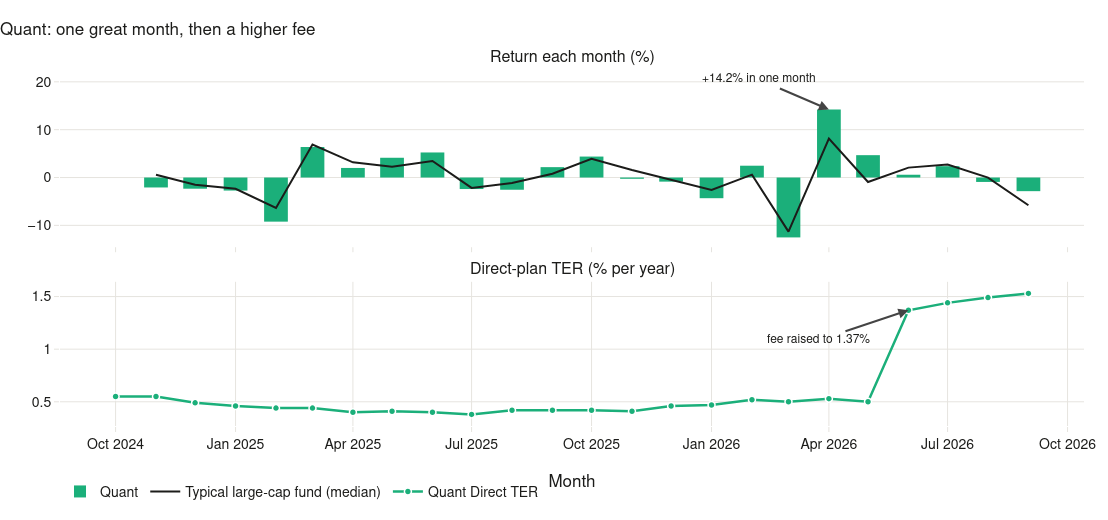

In [12]:
import plotly.express as px
QUANT = "quant large cap fund"
bub = panel[panel["plan"] == "Direct"].dropna(subset=["monthly_return", "dir_ter"]).copy()
bub["ret_pct"] = 100 * bub["monthly_return"]
bub["short"] = bub["name_norm"].map(fund.set_index("name_norm")["short"])
bub["group"] = np.where(bub["name_norm"] == QUANT, "Quant Large Cap", "Other funds")
bub = bub.sort_values(["month", "group"])
fig9 = px.scatter(bub, x="dir_ter", y="ret_pct", size="nav_last", size_max=40,
                  color="group", color_discrete_map={"Other funds": C["grey"], "Quant Large Cap": C["quant"]},
                  animation_frame="month", animation_group="name_norm", hover_name="short",
                  hover_data={"nav_last": ":.2f", "dir_ter": ":.2f", "ret_pct": ":.2f", "group": False, "month": False},
                  range_x=[bub["dir_ter"].min() - 0.1, bub["dir_ter"].max() + 0.1],
                  range_y=[bub["ret_pct"].min() - 1, bub["ret_pct"].max() + 1],
                  labels={"dir_ter": "Direct-plan TER (% per year)", "ret_pct": "Return that month (%)",
                          "nav_last": "NAV (₹ per unit)", "group": ""},
                  title="Fee vs return, month by month (bubble size = NAV per unit)")
fig9.update_traces(marker=dict(line=dict(color="#ffffff", width=1.5), opacity=0.85))
fig9.update_layout(legend=dict(x=0, y=1.02), xaxis_title="Direct-plan TER (% per year)", yaxis_title="Return that month (%)")
fig9.layout.updatemenus[0].buttons[0].args[1]["frame"]["duration"] = 700
fig9.layout.updatemenus[0].buttons[0].args[1]["transition"]["duration"] = 300
fig9.layout.updatemenus[0].update(x=0, y=-0.14, xanchor="left", yanchor="top")
fig9.layout.sliders[0].update(x=0.12, len=0.88, y=-0.12)
save(fig9, "09_bubble_over_time", h=520)

# Quant: return per month (bars) and Direct TER (line), stacked on one month axis
q = panel[(panel["name_norm"] == QUANT) & (panel["plan"] == "Direct")].sort_values("month_dt")
q_med = panel[panel["plan"] == "Direct"].groupby("month_dt")["monthly_return"].median()
q_best_m = q.loc[q["monthly_return"].idxmax()]
q_jump = q[q["dir_ter"].diff() > 0.5].iloc[0] if (q["dir_ter"].diff() > 0.5).any() else None
fig10 = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.1, row_heights=[0.55, 0.45],
                      subplot_titles=("Return each month (%)", "Direct-plan TER (% per year)"))
fig10.add_trace(go.Bar(x=q["month_dt"], y=100 * q["monthly_return"], name="Quant", marker_color=C["quant"],
                       hovertemplate="%{x|%b %Y}: %{y:.1f}%<extra>Quant</extra>"), row=1, col=1)
fig10.add_trace(go.Scatter(x=q_med.index, y=100 * q_med.values, name="Typical large-cap fund (median)", mode="lines",
                           line=dict(color=C["ink"], width=2), hovertemplate="%{x|%b %Y}: %{y:.1f}%<extra>median fund</extra>"), row=1, col=1)
fig10.add_trace(go.Scatter(x=q["month_dt"], y=q["dir_ter"], name="Quant Direct TER", mode="lines+markers",
                           line=dict(color=C["quant"], width=2.5), marker=dict(size=7, line=dict(color="#ffffff", width=1.5)),
                           hovertemplate="%{x|%b %Y}: %{y:.2f}%<extra>TER</extra>"), row=2, col=1)
fig10.add_annotation(x=q_best_m["month_dt"], y=100 * q_best_m["monthly_return"], text=f"+{100*q_best_m['monthly_return']:.1f}% in one month",
                     showarrow=True, arrowhead=2, ax=-70, ay=-30, font=dict(size=12), row=1, col=1)
if q_jump is not None:
    fig10.add_annotation(x=q_jump["month_dt"], y=q_jump["dir_ter"], text=f"fee raised to {q_jump['dir_ter']:.2f}%",
                         showarrow=True, arrowhead=2, ax=-90, ay=30, font=dict(size=12), row=2, col=1)
fig10.update_layout(title="Quant: one great month, then a higher fee", bargap=0.35, legend=dict(orientation="h", y=-0.14, yanchor="top"), margin=dict(b=90))
fig10.update_xaxes(title_text="Month", row=2, col=1)
save(fig10, "10_quant_story", h=520)

## Captions and page text

Every number is an f-string from the data.

In [13]:
r3n = int(top.shape[0])
worst = top.iloc[-1]
q_before = float(q[q["month_dt"] < q_jump["month_dt"]]["dir_ter"].iloc[-1]) if q_jump is not None else float("nan")
captions = {
 "01": f"Same fund, two prices. The orange dot is what you got in the Regular plan, the blue dot in the Direct plan. "
       f"Direct wins in every fund, by about {top['r3_diff'].median():.1f}% a year. But look at the spread between funds: "
       f"{best['short']} made {best['r3_dir']:.1f}% a year, {worst['short']} only {worst['r3_dir']:.1f}%.",
 "02": f"How much funds charge. Regular plans mostly charge around {med_r:.1f}% of your money every year; Direct plans around {med_d:.1f}%. "
       f"That is the whole difference between the two: the Regular plan includes the distributor's commission.",
 "03": f"The extra charge of the Regular plan, fund by fund. It is not the same everywhere: from {g['gap'].min():.2f}% a year at "
       f"{g.iloc[0]['short']} to {g['gap'].max():.2f}% at {g.iloc[-1]['short']}.",
 "04": f"Does an expensive fund earn less? Each dot is a fund. If fees hurt returns, the dots would slope down. They do not "
       f"(p = {fits['Direct'][2]:.2f} for Direct, {fits['Regular'][2]:.2f} for Regular). Across funds, the fee tells you almost nothing about the return.",
 "05": f"The gap between Regular and Direct fees, month by month. It hardly moves: between {gm['med'].min():.2f}% and {gm['med'].max():.2f}% "
       f"in all 24 months. It is a fixed cost, not something that changes with the market.",
 "06": f"₹1,000 put in every month for 24 months, in a typical fund. Direct ended at ₹{end['Direct']:,.0f}, Regular at ₹{end['Regular']:,.0f}. "
       f"The market was flat, so both sit near the ₹{end['invested']:,.0f} invested; the Direct plan still comes out ahead.",
 "07": f"All 31 funds, month by month. They rise and fall together (they hold mostly the same big companies). "
       f"Worst month: {med_path.loc[med_path['ret_pct'].idxmin(),'month_dt']:%b %Y}, {med_path['ret_pct'].min():.0f}%. "
       f"Best: {med_path.loc[med_path['ret_pct'].idxmax(),'month_dt']:%b %Y}, +{med_path['ret_pct'].max():.0f}%. A 1% yearly fee is tiny next to swings like these.",
 "08": f"What cleaning did. We started with {funnel['rows'].iloc[0]:,} daily rows for every fund in India and ended with "
       f"{funnel['rows'].iloc[-1]:,} rows: one per fund, plan and month. On the right, how many ways the same thing was spelled before and after fixing.",
 "09": f"Press play. Each bubble is one fund; left-right is its fee, up-down is that month's return. Every month the whole cloud jumps up or down "
       f"together, while the fees barely move. Quant (green) is the exception: watch it slide to the right in mid-2026.",
 "10": f"Quant earned +{100*q_best_m['monthly_return']:.1f}% in {q_best_m['month_dt']:%B %Y}, far above the typical fund. "
       + (f"Two months later its Direct fee went from {q_before:.2f}% to {q_jump['dir_ter']:.2f}% a year. A good month was followed by a higher price." if q_jump is not None else ""),
}
json.dump(captions, open(LOGS / "plot_captions.json", "w"), indent=2)

INTRO = f"""
<p class="big">Every mutual fund comes in two versions that hold exactly the same shares: a <b>Regular plan</b>, which you buy through an agent whose
commission is built into the fee, and a <b>Direct plan</b>, which you buy from the fund house with no commission.</p>
<p>We asked two simple questions about India's large-cap funds (funds that buy the 100 biggest companies):</p>
<ol>
<li><b>Does a fund that charges more earn less?</b></li>
<li><b>How much does the Regular plan cost you compared with the Direct plan?</b></li>
</ol>
<p>To answer them we took {k_funds} large-cap funds, their daily prices (NAV) and their monthly fees (TER) from AMFI for October 2024 to
September 2026, cleaned and joined the two, and added AMFI's 1-, 3- and 5-year return figures.</p>
"""
DATA_METHODS = f"""
<h3>Where the data came from</h3>
<ul>
<li><b>Daily NAV</b> for every fund in India, from the AMFI NAV portal. Text files, one per month. 1.2 GB.</li>
<li><b>Monthly fees (TER)</b> for every fund, from AMFI's TER page. Carries the NSDL scheme code.</li>
<li><b>Returns over 1, 3, 5 years</b> from AMFI's fund-performance page (Open Ended · Equity · Large Cap), downloaded on 24 Oct 2026.</li>
</ul>
<p>We read both sites' robots.txt (nothing we used is blocked) and AMFI's terms of use (personal, non-commercial use; no guarantee of accuracy).</p>
<h3>How we stored it</h3>
<p>Raw files are kept exactly as downloaded, named by source and month. Working tables are saved as Parquet so dates and numbers keep their types.
A data dictionary lists every column, its unit and its allowed range.</p>
<h3>How we cleaned it</h3>
<ul>
<li><b>Matching the two feeds.</b> They share no ID. We built a name-to-code dictionary from the full fee history, so a fund keeps its identity even after a rename (12 funds were renamed in these two years). It matched 100% of rows.</li>
<li><b>Picking the right rows.</b> Large-cap only (by the SEBI code in the scheme ID), growth option only, both plans.</li>
<li><b>Fixing spellings.</b> 13 spellings of "growth" became one flag; 62 name strings became 31 funds.</li>
<li><b>Missing days.</b> 908 missing cells, all before two funds were launched; none inside any fund's life. A chi-square test and Welch's t-test back this up. Nothing was filled in: a fund has no price before it exists.</li>
<li><b>Odd values.</b> 42 weekend prices removed. Every big daily jump was checked: all 4 happened on days the whole market moved, so none was a data error.</li>
<li><b>Duplicates.</b> None in the price feed; cross-feed duplicates are what the name dictionary resolves.</li>
</ul>
<p>Every step is in <code>logs/cleaning_log.csv</code> with the number of rows it touched: {len(clog)} steps, {funnel['rows'].iloc[0]:,} rows in, {funnel['rows'].iloc[-1]:,} out.</p>
"""
RESULTS_LEAD = f"""
<ul class="big">
<li><b>Which fund you pick matters most.</b> Over 3 years, {best['short']} made {best['r3_dir']:.1f}% a year and {worst['short']} {worst['r3_dir']:.1f}%.</li>
<li><b>The fee does not tell you which fund will win.</b> Expensive funds did not earn less than cheap ones.</li>
<li><b>Inside a fund, the fee is the whole story.</b> The Regular plan charges about {k_gap_ter:.1f}% a year more and earns about {k_gap_ret:.1f}% a year less, every month, in every fund.</li>
</ul>
"""
CONCLUSION = f"""
<p class="big"><b>1. Pick the fund by how well it has done. 2. If two funds have done about the same, take the one with the lower fee. 3. Whichever fund you pick, buy its Direct plan.</b></p>
<h3>Why fund first</h3>
<p>The best large-cap fund made {best['r3_dir']:.1f}% a year over 3 years; the worst made {k_worst['r3_dir']:.1f}%. That is a gap of
{best['r3_dir'] - k_worst['r3_dir']:.1f}% every year, and the fee had nothing to do with it: cheap funds were not better, expensive funds were not worse.
So the fee cannot tell you which fund to pick. The track record can.</p>
<h3>Why fee second</h3>
<p>When two funds have done about the same, the fee is the only thing left that separates them, and it is paid every year whether the market
goes up or down. Between two similar funds, the cheaper one leaves more in your pocket.</p>
<h3>Why always Direct</h3>
<p>The Regular plan of a fund charges about {k_gap_ter:.1f}% of your money more every year than the Direct plan of the same fund, for the same shares.
That cost comes straight out of your return: about {k_gap_ret:.1f}% a year less. On ₹1,000 a month it was ₹{end['Direct'] - end['Regular']:,.0f}
after two years in a flat market; over ten years in a normal market it is about {ten_yr_pct:.0f}% of your final amount.</p>
<p><b>Short answer to the project question:</b> a costlier fund does not earn less than a cheaper fund, but a costlier plan of the same fund
does, by exactly the extra fee: about {k_gap_ter:.1f}% a year, between {g['gap'].min():.2f}% and {g['gap'].max():.2f}% depending on the fund.</p>
"""
LIMITATIONS = """
<ul>
<li><b>Only two years of fee data.</b> AMFI's fee feed is complete only from October 2024. We used AMFI's 3-year return figures to look further back, but those are a snapshot, not a series.</li>
<li><b>Only 31 funds</b> (28 with a 3-year record). Enough to see the pattern, not enough to rule out a very small fee effect.</li>
<li><b>Funds that closed or merged before October 2024</b> are not here.</li>
<li><b>Large cap only.</b> Mid-cap and small-cap funds charge differently and vary more.</li>
<li><b>The two feeds were matched by name</b>, not by an official ID. It worked for every row here, and the rule is written down in the cleaning notebook.</li>
</ul>
"""
DESIGN = f"""
<h3>How the charts are designed</h3>
<p>Blue always means Direct plan, orange always means Regular plan, grey means background. The two colours differ in brightness too, so they still read in black and white
and for colour-blind readers (checked, ΔE 15.7). Where one fund is the point, only it gets a colour. Charts that belong together sit side by side on one grid.
No dual axes, no cut-off axes. Every chart says its main number in the title and its units on the axes.</p>
"""

## Returns-since-launch table

Its own page, `clean/performance_table.html`: fund, Regular since launch, Direct since launch.

In [14]:
tb = fund.sort_values("rsl_dir", ascending=False, na_position="last")
rows_html = "".join(
    f"<tr><td class='l'>{escape(str(r['short']))}</td><td>{fmt(r['rsl_reg'], 2)}</td><td>{fmt(r['rsl_dir'], 2)}</td></tr>"
    for _, r in tb.iterrows())
table_core = f"""<table id="perf"><thead><tr><th class="l">Fund</th><th>Regular plan, since launch<br><span>% per year</span></th>
<th>Direct plan, since launch<br><span>% per year</span></th></tr></thead><tbody>{rows_html}</tbody></table>"""
table_note = (f"Average yearly return since each plan started, from AMFI's fund-performance page ({perf_date}). Direct plans only began in January 2013, "
              f"so where a Regular plan is older its figure covers a longer, different period. That is why Regular sometimes shows a higher number here; "
              f"for a fair comparison use the 3-year chart on the Results tab.")
table_page = f"""<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Since-launch returns</title>{FONT_LINK}<style>{css}
#perf td,#perf th{{text-align:right}} #perf td.l,#perf th.l{{text-align:left}}</style></head><body>
<header><h1>Returns since launch, Regular vs Direct</h1><p class="q">{k_funds} large-cap funds · AMFI fund-performance snapshot {perf_date}</p>
<p class="meta"><a href="dashboard.html">Back to the dashboard</a></p></header>
<main><div class="tablewrap" style="display:inline-block;min-width:720px">{table_core}</div><p class="note" style="max-width:760px">{table_note}</p></main>
<script>{js}</script></body></html>"""
(CLEAN / "performance_table.html").write_text(table_page, encoding="utf-8")
print("wrote clean/performance_table.html")

wrote clean/performance_table.html


## Static page

`clean/dashboard.html`: hero, six sections, ten plots in a two-column grid.

In [15]:
FIGS = {"01": fig1, "02": fig2, "03": fig3, "04": fig4, "05": fig5, "06": fig6, "07": fig7, "08": fig8, "09": fig9, "10": fig10}
HEADS = {"01": "Same fund, two prices", "02": "What funds charge", "03": "The Regular plan's extra charge, fund by fund",
         "04": "Does paying more get you more?", "05": "The gap never moves", "06": "₹1,000 a month, two years",
         "07": "All funds move together", "08": "Before and after cleaning", "09": "Fee vs return, in motion", "10": "Quant's story"}
ROWS = [["01", "03"], ["04"], ["02", "05"], ["09", "10"], ["07", "06"], ["08"]]
HEIGHTS = {"01": 640, "03": 640, "04": 420, "02": 380, "05": 380, "09": 520, "10": 520, "07": 400, "06": 400, "08": 400}
for k, f in FIGS.items():
    f.update_layout(height=HEIGHTS[k], title=None, margin=dict(t=48))

def fig_card(k):
    return (f"<figure><h4>{escape(HEADS[k])}</h4><div class='plot'>{frag(FIGS[k])}</div>"
            f"<figcaption>{escape(captions[k])}</figcaption></figure>")
results_grid = "".join(f"<div class='row2'>{''.join(fig_card(k) for k in row)}</div>" for row in ROWS)
def prose(num, title, body):
    return f"<section id='s{num}'><h2>{escape(title)}</h2><div class='prose'>{body}</div></section>"
html = f"""<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Large-cap fund costs and returns</title>{FONT_LINK}<style>{css}</style><script>{plotlyjs}</script></head><body>
<header class="hero">
<div class="wrap">
<p class="eyebrow">Mutual fund costs and returns · large-cap funds · India</p>
<h1>Does a costlier fund earn you less?<br>And what does the Regular plan really cost?</h1>
<div class="stats">{''.join(f"<div class='stat'><div class='v'>{v}</div><div class='l'>{l}</div></div>" for l, v, s in kpis)}</div>
<p class="meta">{k_funds} funds · AMFI data, Oct 2024 to Sep 2026 · <a href="performance_table.html">Returns since launch, by fund</a></p>
</div></header>
<nav><div class="wrap"><a href="#s1">Introduction</a><a href="#s2">Data and methods</a><a href="#s3">Results</a><a href="#s4">Conclusion</a>
<a href="#s5">Limitations</a><a href="#s6">Attributions</a></div></nav>
<main class="wrap">
{prose(1, "Introduction", INTRO)}
{prose(2, "Data and methods", DATA_METHODS + DESIGN)}
<section id="s3"><h2>Results</h2><div class="prose">{RESULTS_LEAD}</div>{results_grid}</section>
{prose(4, "Conclusion", CONCLUSION)}
{prose(5, "Limitations", LIMITATIONS)}
{prose(6, "Attributions", attribution)}
</main>
<footer>Built from <code>notebooks/03_visualisation.ipynb</code>. Every number on this page is computed from the data; nothing is typed in.</footer>
</body></html>"""
(CLEAN / "dashboard.html").write_text(html, encoding="utf-8")
print("wrote clean/dashboard.html:", f"{len(html)/1e6:.1f} MB (plotly.js inlined, works offline)")

wrote clean/dashboard.html: 5.1 MB (plotly.js inlined, works offline)


## The Dash site

Run this cell and open http://127.0.0.1:8050. Tabs follow the presentation order. In Results, under *Pick a fund*, click a line to highlight that fund in both charts; Reset clears. Stop the server (stop button or kernel restart) before re-running.

In [16]:
from dash import Dash, html as dh, dcc, Input, Output, ctx
import dash_bootstrap_components as dbc

ld_all = panel[panel["plan"] == "Direct"].dropna(subset=["monthly_return"]).sort_values(["name_norm", "month_dt"]).copy()
ld_all["ret_pct"] = 100 * ld_all["monthly_return"]
fund_list = sorted(ld_all["name_norm"].unique())
short_of = fund.set_index("name_norm")["short"].to_dict()

def fig_highlight(selected=None):
    f = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.1, row_heights=[0.6, 0.4],
                      subplot_titles=("Return each month, Direct plan (%)", "Direct-plan fee, TER (% per year)"))
    for n in fund_list:
        sub = ld_all[ld_all["name_norm"] == n]
        sel = (n == selected)
        style = dict(color=C["direct"] if sel else C["grey"], width=2.5 if sel else 1.2)
        for row, col in [(1, "ret_pct"), (2, "dir_ter")]:
            f.add_trace(go.Scatter(x=sub["month_dt"], y=sub[col], mode="lines+markers" if sel else "lines", line=style,
                                   marker=dict(size=7, line=dict(color="#ffffff", width=1.5)) if sel else None,
                                   opacity=1.0 if sel else (0.35 if selected is None else 0.18),
                                   name=short_of[n], customdata=[n] * len(sub), showlegend=False,
                                   hovertemplate=f"{short_of[n]}<br>%{{x|%b %Y}}: %{{y:.2f}}<extra></extra>"), row=row, col=1)
    f.update_layout(height=520, hovermode="closest", clickmode="event", margin=dict(t=60),
                    title=(f"{short_of[selected]}" if selected else "Click any line to pick a fund"))
    f.update_xaxes(title_text="Month", row=2, col=1)
    return f

def fig_sip(selected=None):
    f = go.Figure()
    for n in fund_list:
        for pl in ["Regular", "Direct"]:
            s_ = sip[(sip["name_norm"] == n) & (sip["plan"] == pl)]
            sel = (n == selected)
            f.add_trace(go.Scatter(x=s_["month_dt"], y=s_["value"], mode="lines+markers" if sel else "lines",
                                   line=dict(color=(C[pl.lower()] if sel else C["grey"]), width=2.5 if sel else 1),
                                   marker=dict(size=6, line=dict(color="#ffffff", width=1.5)) if sel else None,
                                   opacity=1.0 if sel else (0.3 if selected is None else 0.12),
                                   name=f"{pl} plan" if sel else short_of[n], customdata=[n] * len(s_), showlegend=sel,
                                   hovertemplate=f"{short_of[n]} {pl}<br>%{{x|%b %Y}}: ₹%{{y:,.0f}}<extra></extra>"))
    f.add_trace(go.Scatter(x=sipm["month_dt"], y=sipm["invested"], mode="lines", name="Money put in",
                           line=dict(color=C["ink"], width=2, dash="dot"), hovertemplate="%{x|%b %Y}<br>put in ₹%{y:,.0f}<extra></extra>"))
    if selected:
        s_ = sip[sip["name_norm"] == selected]
        e = {pl: float(s_[s_["plan"] == pl]["value"].iloc[-1]) for pl in ["Regular", "Direct"]}
        t = f"{short_of[selected]}: Direct ₹{e['Direct']:,.0f} vs Regular ₹{e['Regular']:,.0f}"
    else:
        t = "Click a line to see one fund's two plans"
    f.update_layout(height=460, hovermode="closest", clickmode="event", title=t, xaxis_title="Month", yaxis_title="Value of ₹1,000 a month (₹)",
                    legend=dict(orientation="h", y=-0.25, yanchor="top"), margin=dict(t=60, b=90))
    return f

def card(k, h=None):
    f = FIGS[k]
    if h:
        f.update_layout(height=h)
    return dbc.Col(dbc.Card([dbc.CardBody([dh.H5(HEADS[k], className="card-title"),
                                           dcc.Graph(figure=f, config={"displaylogo": False, "responsive": True}),
                                           dh.P(captions[k], className="cap")])], className="viz"),
                   lg=12 if len([r for r in ROWS if k in r][0]) == 1 else 6, className="mb-4")
def prose_card(inner, wide=False):
    return dbc.Card(dbc.CardBody(dcc.Markdown(inner, dangerously_allow_html=True)), className="prose mb-4",
                    style={} if wide else {"maxWidth": "900px"})
def stat(l, v, s):
    return dbc.Col(dh.Div([dh.Div(v, className="v"), dh.Div(l, className="l"), dh.Div(s, className="s")], className="stat"), md=3, xs=6)

perf_table = dbc.Table([dh.Thead(dh.Tr([dh.Th("Fund"), dh.Th("Regular plan, since launch (% a year)"), dh.Th("Direct plan, since launch (% a year)")])),
                        dh.Tbody([dh.Tr([dh.Td(r["short"]), dh.Td("" if pd.isna(r["rsl_reg"]) else f"{r['rsl_reg']:.2f}"),
                                         dh.Td("" if pd.isna(r["rsl_dir"]) else f"{r['rsl_dir']:.2f}")]) for _, r in tb.iterrows()])],
                       hover=True, size="sm", className="perf")

results_rows = [dbc.Row([card(k) for k in row]) for row in ROWS]
explore = [dh.H4("Pick a fund", className="mt-2 mb-1"),
           dh.P("Click any line to see that fund's monthly return, its fee, and what a ₹1,000 monthly SIP would have become in each plan.", className="text-secondary"),
           dbc.Button("Reset", id="reset", size="sm", color="secondary", className="mb-3"),
           dbc.Row([dbc.Col(dbc.Card(dbc.CardBody(dcc.Graph(id="g-highlight", figure=fig_highlight(), config={"displaylogo": False})), className="viz"), lg=6, className="mb-4"),
                    dbc.Col(dbc.Card(dbc.CardBody(dcc.Graph(id="g-sip", figure=fig_sip(), config={"displaylogo": False})), className="viz"), lg=6, className="mb-4")])]

app = Dash(__name__, external_stylesheets=[dbc.themes.FLATLY], title="Large-cap fund costs and returns")
app.index_string = f"""<!DOCTYPE html><html><head>{{%metas%}}<title>{{%title%}}</title>{{%favicon%}}{{%css%}}{FONT_LINK}<style>{DASH_CSS}</style></head>
<body>{{%app_entry%}}<footer>{{%config%}}{{%scripts%}}{{%renderer%}}</footer></body></html>"""
app.layout = dh.Div([
    dh.Div(dbc.Container([
        dh.P("Mutual fund costs and returns · large-cap funds · India", className="eyebrow"),
        dh.H1(["Does a costlier fund earn you less?", dh.Br(), "And what does the Regular plan really cost?"]),
        dbc.Row([stat(l, v, s) for l, v, s in kpis], className="stats"),
        dh.P(f"{k_funds} funds · AMFI data, Oct 2024 to Sep 2026", className="meta"),
    ], fluid=False), className="hero"),
    dbc.Container(dbc.Tabs([
        dbc.Tab(prose_card(INTRO), label="Introduction", tab_class_name="tab"),
        dbc.Tab(prose_card(DATA_METHODS + DESIGN), label="Data and methods", tab_class_name="tab"),
        dbc.Tab([prose_card(RESULTS_LEAD, wide=True)] + results_rows + explore, label="Results", tab_class_name="tab"),
        dbc.Tab(prose_card(CONCLUSION), label="Conclusion", tab_class_name="tab"),
        dbc.Tab(prose_card(LIMITATIONS), label="Limitations", tab_class_name="tab"),
        dbc.Tab(dbc.Card(dbc.CardBody([dh.P(table_note, className="text-secondary"), perf_table]), className="prose mb-4", style={"maxWidth": "820px"}),
                label="Returns since launch", tab_class_name="tab"),
        dbc.Tab(prose_card(attribution), label="Attributions", tab_class_name="tab"),
    ], className="tabs mt-4 mb-3"), fluid=False, className="pb-5"),
])

@app.callback(Output("g-highlight", "figure"), Output("g-sip", "figure"),
              Input("g-highlight", "clickData"), Input("g-sip", "clickData"), Input("reset", "n_clicks"))
def _select(c1, c2, _n):
    trig = ctx.triggered_id
    sel = None
    if trig == "g-highlight" and c1:
        sel = c1["points"][0].get("customdata")
    elif trig == "g-sip" and c2:
        sel = c2["points"][0].get("customdata")
    if isinstance(sel, list):
        sel = sel[0]
    if sel not in fund_list:
        sel = None
    return fig_highlight(sel), fig_sip(sel)

app.run(debug=False, port=8050, jupyter_mode="external")

Dash app running on http://127.0.0.1:8050/
